<a href="https://colab.research.google.com/github/studiousdoston/computer_vision/blob/main/pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
pip install torch


In [1]:
import torch

In [3]:
print(torch.__version__)

2.11.0+cu130


In [5]:
print("CUDA available:", torch.cuda.is_available())

CUDA available: True


#Scalar

In [18]:
scalar = torch.tensor(5)
print("scalar", scalar)
print("Shape:",scalar.shape)
print("Number of dimensions:", scalar.ndim)
print("Size:", scalar.size())


scalar tensor(5)
Shape: torch.Size([])
Number of dimensions: 0
Size: torch.Size([])


# Vector

In [17]:
vector = torch.tensor([1, 2, 3])
print("vector", vector)
print("Shape:",vector.shape)
print("Number of dimensions:", vector.ndim)
print("Size:", vector.size())

vector tensor([1, 2, 3])
Shape: torch.Size([3])
Number of dimensions: 1
Size: torch.Size([3])


# MATRIX

In [19]:
MATRIX = torch.tensor([[1, 2, 3],[4, 5, 6]])
print("MATRIX:", MATRIX)
print("Shape:",MATRIX.shape)
print("Number of dimensions:", MATRIX.ndim)
print("Size:", MATRIX.size())

MATRIX: tensor([[1, 2, 3],
        [4, 5, 6]])
Shape: torch.Size([2, 3])
Number of dimensions: 2
Size: torch.Size([2, 3])


# Tensor

In [20]:
tensor3d = torch.stack([MATRIX,  MATRIX +10])
print("Tensor: ", tensor3d)
print("Shape:",tensor3d.shape)
print("Number of dimensions:", tensor3d.ndim)
print("Size:", tensor3d.size())

Tensor:  tensor([[[ 1,  2,  3],
         [ 4,  5,  6]],

        [[11, 12, 13],
         [14, 15, 16]]])
Shape: torch.Size([2, 2, 3])
Number of dimensions: 3
Size: torch.Size([2, 2, 3])


# Random Numbers

In [25]:
random_numbers = torch.rand(2, 3)
print("Random Numbers: ", random_numbers)
print("Data types:", random_numbers.dtype)
print("Device of random_numbers:", random_numbers.device)

Random Numbers:  tensor([[0.6853, 0.8861, 0.4501],
        [0.3110, 0.1854, 0.4460]])
Data types: torch.float32
Device of random_numbers cpu


# Zeros

In [22]:
print("Zeros:", torch.zeros(3, 3))

Zeros: tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])


# Ones

In [23]:
print("Ones:", torch.ones(2, 4))

Ones: tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.]])


# Addition | Multiplication

In [32]:
x = torch.tensor([[1, 2], [3, 4]])
y = torch.tensor([[5, 6], [7, 8]])

# Element-wise addition
print("Addition:\n ", x + y)

print("\n---------------------------- ")

# Element-wise mulitplication
print("Multiplication: \n ", x * y)

print("\n---------------------------- ")

# Matrix mulitplication
print("Matrix @ Multiplication : \n ", torch.matmul(x ,y))




Addition:
  tensor([[ 6,  8],
        [10, 12]])

---------------------------- 
Multiplication: 
  tensor([[ 5, 12],
        [21, 32]])

---------------------------- 
Matrix @ Multiplication : 
  tensor([[19, 22],
        [43, 50]])


# Neural Networks Pytorch

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.__version__


'2.11.0+cpu'

In [2]:
# Setup device agnostic code
device = "cude" if torch.cuda.is_available() else "cpu"
print(f"using device: {device}" )

using device: cpu


In [5]:
# Creat weight and bias
weight = 0.7
bias =0.3

# Create range values
start = 0
end = 1
step= 0.02

# Create X and Y (features and labels)
X = torch.arange(start, end, step).unsqueeze(dim=1) # without unsqueeze, errors will happen later on (shapes within linear layers)
Y = weight * X + bias

# Linear Regression: y = wx + b
print("X:", X),

print("\n Y:", Y)

# Split data
train_split = int(0.8 * len(X)) # 10_000(100%) data => 8_000(80%) train | 2_000(20%) testing
X_train, Y_train = X[:train_split], Y[:train_split] # for training
X_test, Y_test = X[train_split:], Y[train_split:] # for testing


len(X_train), len(Y_train), len(X_test), len(Y_test)

X: tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800],
        [0.2000],
        [0.2200],
        [0.2400],
        [0.2600],
        [0.2800],
        [0.3000],
        [0.3200],
        [0.3400],
        [0.3600],
        [0.3800],
        [0.4000],
        [0.4200],
        [0.4400],
        [0.4600],
        [0.4800],
        [0.5000],
        [0.5200],
        [0.5400],
        [0.5600],
        [0.5800],
        [0.6000],
        [0.6200],
        [0.6400],
        [0.6600],
        [0.6800],
        [0.7000],
        [0.7200],
        [0.7400],
        [0.7600],
        [0.7800],
        [0.8000],
        [0.8200],
        [0.8400],
        [0.8600],
        [0.8800],
        [0.9000],
        [0.9200],
        [0.9400],
        [0.9600],
        [0.9800]])

 Y: tensor([[0.3000],
        [0.3140],
        [0.3280],
        [0.3420],
        [0.3560],
 

(40, 40, 10, 10)

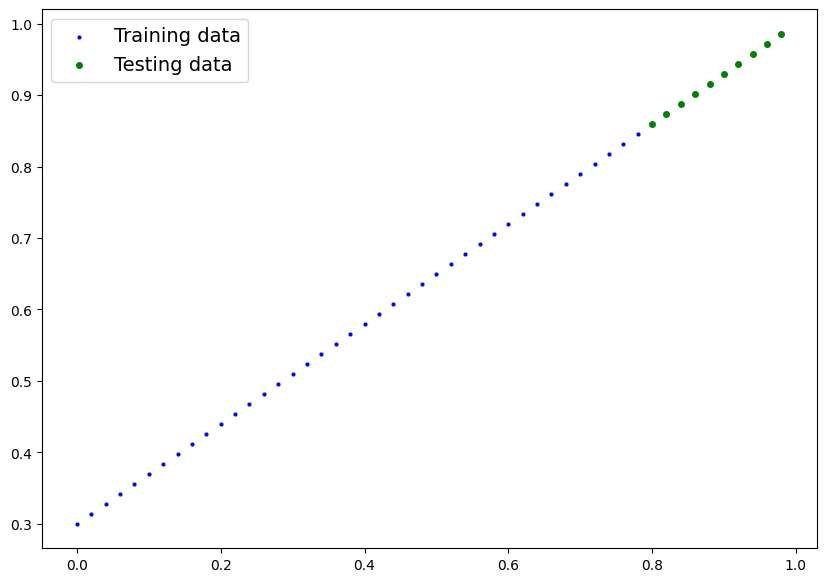

In [45]:
def plot_predictions(train_data = X_train, train_labels = Y_train,
                     test_data = X_test, test_labels = Y_test, predictions=None):
    plt.figure(figsize=(10,7))

    # Plot training data in blue
    plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")

    # Plot testing data in blue
    plt.scatter(test_data, test_labels, c="g", s=16, label="Testing data")

    if predictions is not None:
       plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

    plt.legend(prop={"size":14})


plot_predictions()


In [17]:
# Subclass nn.Module to make our model
class LinearRegressionModelV2(nn.Module):
  def __init__(self):
      super().__init__()
      # Use nn.Linear() for creating the model parameters
      self.linear_layer = nn.Linear(in_features=1, out_features=1) # Linear -> y=wx+b

  # Define the forward computation (input data x flows through nn.Linear())
  def forward(self, x: torch.Tensor) -> torch.Tensor:
      return self.linear_layer(x)


# Set the manual seed when creating the model (this is not always needed but is used for demonstrative purposes, try commenting it out and see what happens)
torch.manual_seed(42)
model_1 = LinearRegressionModelV2()
model_1, model_1.state_dict()

(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [37]:
# Create loss function
loss_fn = nn.L1Loss()

# Create optimizer
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.01) # optimize newly created model's parameters

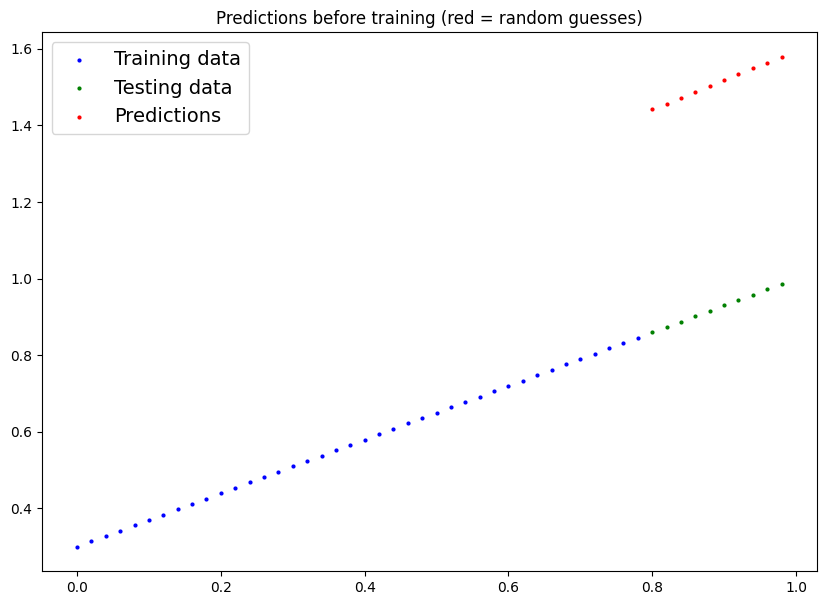

In [38]:
# See model's untrained predictions (on test set)
model_1.eval()
with torch.inference_mode():
    y_preds_early = model_1(X_test) # backwards

plot_predictions(predictions=y_preds_early)
plt.title("Predictions before training (red = random guesses)")
plt.show()

In [39]:
# Set the number of epochs
epochs = 1000

# Put data on the available device
# Without this, error will happen
X_train = X_train.to(device)
X_test = X_test.to(device)
Y_train = Y_train.to(device)
Y_test = Y_test.to(device)


for epoch in range(epochs):
  ### Training
  model_1.train()

  # 1. Forward pass
  y_pred = model_1(X_train)

  # 2. Calculate loss
  loss = loss_fn(y_pred, Y_train)

  # 3. Zero gradient optimizer
  optimizer.zero_grad()

  # 4. Loss backward
  loss.backward()

  # 5. Step the optimizer
  optimizer.step()

  ### Testing
  model_1.eval() # put the model in evaluation mode for testing (inference)
  # 1. Forward pass
  with torch.inference_mode():
      test_pred = model_1(X_test)

      # 2. Calculate test loss (no backward here; we never train on test data)
      test_loss = loss_fn(test_pred, Y_test)

  if epoch % 100 == 0:
      print(f"Epoch: {epoch} |  Train loss: {loss} | Test loss: {test_loss}")




Epoch: 0 |  Train loss: 0.5551779866218567 | Test loss: 0.5739762187004089
Epoch: 100 |  Train loss: 0.006215679459273815 | Test loss: 0.014086711220443249
Epoch: 200 |  Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 300 |  Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 400 |  Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 500 |  Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 600 |  Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 700 |  Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 800 |  Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
Epoch: 900 |  Train loss: 0.0012645035749301314 | Test loss: 0.013801807537674904


In [40]:
# Turn model into evaluation mode
model_1.eval()

# Make predictions on the test data
with torch.inference_mode():
    y_pred = model_1(X_test)
y_pred


tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]])

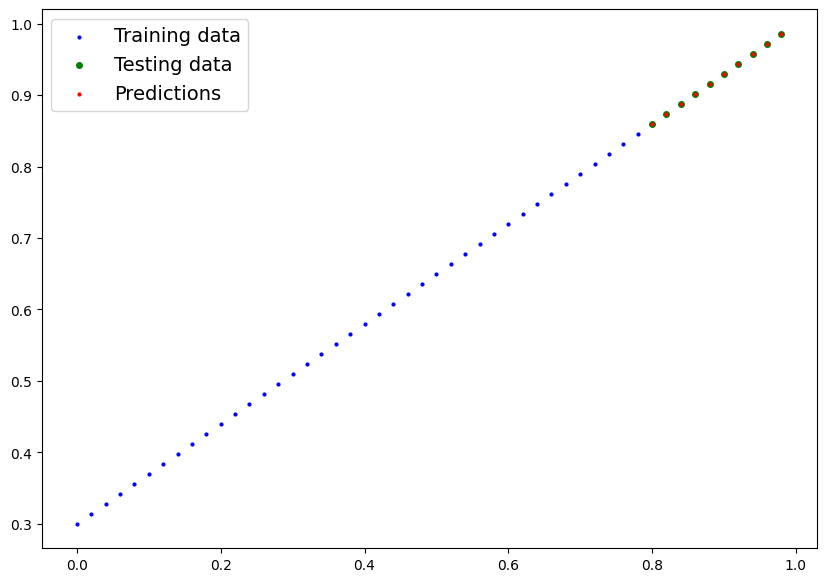

In [46]:
# Put data on CPU and plot it
plot_predictions(predictions=y_pred)

In [48]:
torch.save(model_1.state_dict(), "trained_model.pth")

In [49]:
loaded_model = LinearRegressionModelV2()

loaded_model.load_state_dict(torch.load('/content/trained_model.pth'))
loaded_model.eval()

LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)